# A minimum-change rank-one edit

Impose a new output at one key while measuring how the edit affects other inputs.

For a nonzero key k with desired residual e, the minimum-Frobenius-norm update is e kᵀ / (kᵀk). Every row solves one minimum-norm linear constraint. Orthogonal inputs are unchanged. This is a single linear-layer derivation related to rank-one editing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

## Construct the weights and test their behaviour

Inspect the arrays and the reference output. Each check describes a specific property of the constructed model.

rank 1 key residual 2.220446049250313e-16 orthogonal drift 0.0


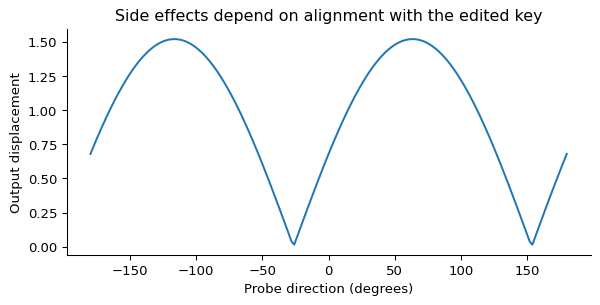

In [2]:
W = np.array([[1.0, -0.3], [0.4, 0.8]])
key = np.array([1.0, 2.0])
target = np.array([2.0, -1.0])
delta = np.outer(target - W @ key, key) / (key @ key)
Wp = W + delta
orth = np.array([-2.0, 1.0])
assert np.allclose(Wp @ key, target) and np.allclose(Wp @ orth, W @ orth)
angles = np.linspace(-np.pi, np.pi, 181)
X = np.stack([np.cos(angles), np.sin(angles)])
drift = np.linalg.norm(delta @ X, axis=0)
print(
    "rank",
    np.linalg.matrix_rank(delta),
    "key residual",
    np.linalg.norm(Wp @ key - target),
    "orthogonal drift",
    np.linalg.norm(delta @ orth),
)
fig, ax = plt.subplots(figsize=(6.2, 3.1), constrained_layout=True)
ax.plot(np.degrees(angles), drift)
ax.set(
    xlabel="Probe direction (degrees)",
    ylabel="Output displacement",
    title="Side effects depend on alignment with the edited key",
)
plt.show()

## Interpreting the result

A successful edit at the key does not guarantee locality on nearby inputs. The plotted directions measure that side effect directly.

## Exercise

Find the directions with zero drift analytically and compare with the curve.

## References

[Meng et al., Locating and Editing Factual Associations in GPT (2022)](https://arxiv.org/abs/2202.05262)

[WeightCode, weight-space programming preprint (2026)](https://arxiv.org/abs/2611.25476)